In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

df = pd.read_csv("scores.csv")
df

,Model,Band,Segment Size,FS,Parameters,Fine Score,Coarse Score
0,PUNet,0-3,40000,10000000,6968008,-13.854050,-2.770810
1,PUNet,4-9,40000,10000000,6968008,3.862517,3.944289
2,PUNet,10-14,40000,10000000,6968008,1.411889,1.526366
3,PUNet,15-19,40000,10000000,6968008,4.672920,4.749727
4,FCNet,0-3,40000,10000000,323280840,1.957063,2.410341
5,FCNet,4-9,40000,10000000,323280840,5.374741,5.362625
6,FCNet,10-14,40000,10000000,323280840,7.476336,7.555209
7,FCNet,15-19,40000,10000000,323280840,7.419254,7.549555


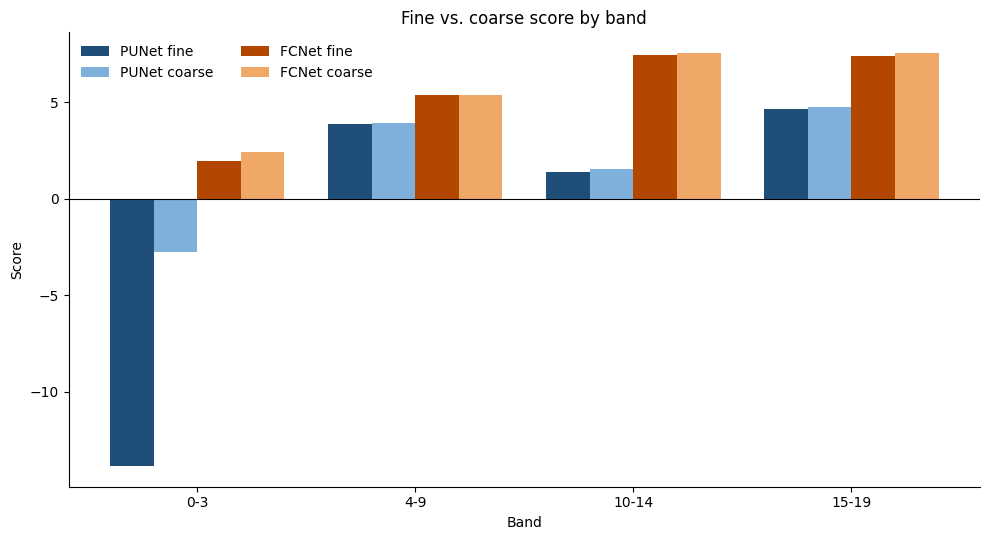

In [2]:
bands = list(df["Band"].unique())
models = list(df["Model"].unique())
score_cols = ["Fine Score", "Coarse Score"]

series = [(m, s) for m in models for s in score_cols]
colors = {
    ("PUNet", "Fine Score"): "#1f4e79",
    ("PUNet", "Coarse Score"): "#7fb0dc",
    ("FCNet", "Fine Score"): "#b34700",
    ("FCNet", "Coarse Score"): "#f0a868",
}

x = np.arange(len(bands))
width = 0.8 / len(series)

fig, ax = plt.subplots(figsize=(10, 5.5))

for i, (model, col) in enumerate(series):
    vals = (
        df[df["Model"] == model]
        .set_index("Band")
        .loc[bands, col]
        .values
    )
    offset = (i - (len(series) - 1) / 2) * width
    ax.bar(
        x + offset,
        vals,
        width,
        label=f"{model} {col.split()[0].lower()}",
        color=colors[(model, col)],
    )

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(bands)
ax.set_xlabel("Band")
ax.set_ylabel("Score")
ax.set_title("Fine vs. coarse score by band")
ax.legend(ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
#plt.savefig("scores_plot.png", dpi=200)
plt.show()